# Member 3: WIS, patient-cluster bootstrap and limitations

Run Members 1 and 2 first. Sensitivity uses validation data. The predeclared final policy is evaluated on test data without choosing settings to improve test results.

In [1]:
import json
import os
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, display

root = next((path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'main_pipeline.py').is_file()), None)
if root is None:
    raise RuntimeError("Open this notebook from the project root or a member folder")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from main_pipeline import load_configs, prepare_data, train_model, evaluate_model

output = Path(os.environ.get('ASS2_OUTPUT_DIR', root)).resolve()
print("Source: synthetic coursework demo; no clinical efficacy claim.")
print("Output:", output)


Source: synthetic coursework demo; no clinical efficacy claim.
Output: C:\Users\ADMIN\Desktop\ass2


## 1. Evaluate the saved policy

WIS normalizes trajectory log-weights without flooring small values. The target is the softened policy, not the deterministic training policy. Behavior probabilities are estimates; smoothing does not establish causal identification or true overlap.

In [2]:
results = evaluate_model(output)
metrics = json.loads((output / 'artifacts/evaluation_metrics.json').read_text())
display(metrics)
if results['low_ess']:
    print("WARNING: Low ESS. Bootstrap confidence intervals do not establish policy superiority.")


{'point_wis': 91.48082548816491,
 'point_clinician': 80.72883139662191,
 'ess': 1.8960554429945284,
 'n_patients': 90,
 'n_episodes': 90,
 'low_ess': True,
 'clipped_episodes': 0,
 'invalid_bootstraps': 0,
 'confidence_level': 0.95,
 'wis_median': 91.4811774981156,
 'wis_ci_lower': 88.63748761423216,
 'wis_ci_upper': 93.20640716854692,
 'clin_median': 80.76748154664145,
 'clin_ci_lower': 72.7050116114788,
 'clin_ci_upper': 86.94619380383791,
 'data_source': 'synthetic',
 'estimand': 'episode return; patient-cluster bootstrap',
 'clinical_efficacy_established': False,
 'sensitivity_split': 'validation'}

## 2. Uncertainty and the estimand

The baseline is the observed mean discounted episode return. The target uses WIS over episodes. Bootstrap samples patients and retains every ICU stay per sampled patient. An all-zero-support replicate is counted as invalid, not replaced by zero.

In [3]:
pd.DataFrame({
    'observed behavior': [results['point_clinician'], results['clin_median'], results['clin_ci_lower'], results['clin_ci_upper']],
    'soft target WIS': [results['point_wis'], results['wis_median'], results['wis_ci_lower'], results['wis_ci_upper']],
}, index=['point', 'bootstrap median', 'CI lower', 'CI upper'])


,observed behavior,soft target WIS
point,80.728831,91.480825
bootstrap median,80.767482,91.481177
CI lower,72.705012,88.637488
CI upper,86.946194,93.206407


## 3. Validation sensitivity

Alpha, absolute trajectory-weight clipping and soft target probability are varied one at a time. Equal values across clipping settings can mean no weights were clipped; that is not proof of robustness.

In [4]:
pd.read_csv(output / 'data/sensitivity_analysis.csv')


,split,param_type,param_value,wis_value,clinician_value,ess,clipped_episodes,low_ess
0,validation,alpha,0.01,93.205738,80.732598,1.237369,0,True
1,validation,alpha,0.05,93.204255,80.732598,1.702804,0,True
2,validation,alpha,0.10,93.205176,80.732598,1.123104,0,True
3,validation,alpha,0.20,93.205830,80.732598,1.027155,0,True
4,validation,weight_clip,100.00,93.204255,80.732598,1.702804,0,True
5,validation,weight_clip,250.00,93.204255,80.732598,1.702804,0,True
6,validation,weight_clip,500.00,93.204255,80.732598,1.702804,0,True
7,validation,weight_clip,1000.00,93.204255,80.732598,1.702804,0,True
8,validation,soft_prob,0.95,93.098243,80.732598,2.164434,0,True
9,validation,soft_prob,0.98,93.196062,80.732598,2.725873,0,True


## 4. Diagnostic figures

Mortality plots show simulated associations by mean action-bin discrepancy, not physical dose differences or causal treatment effects. Counts and Wilson intervals expose sparse groups.

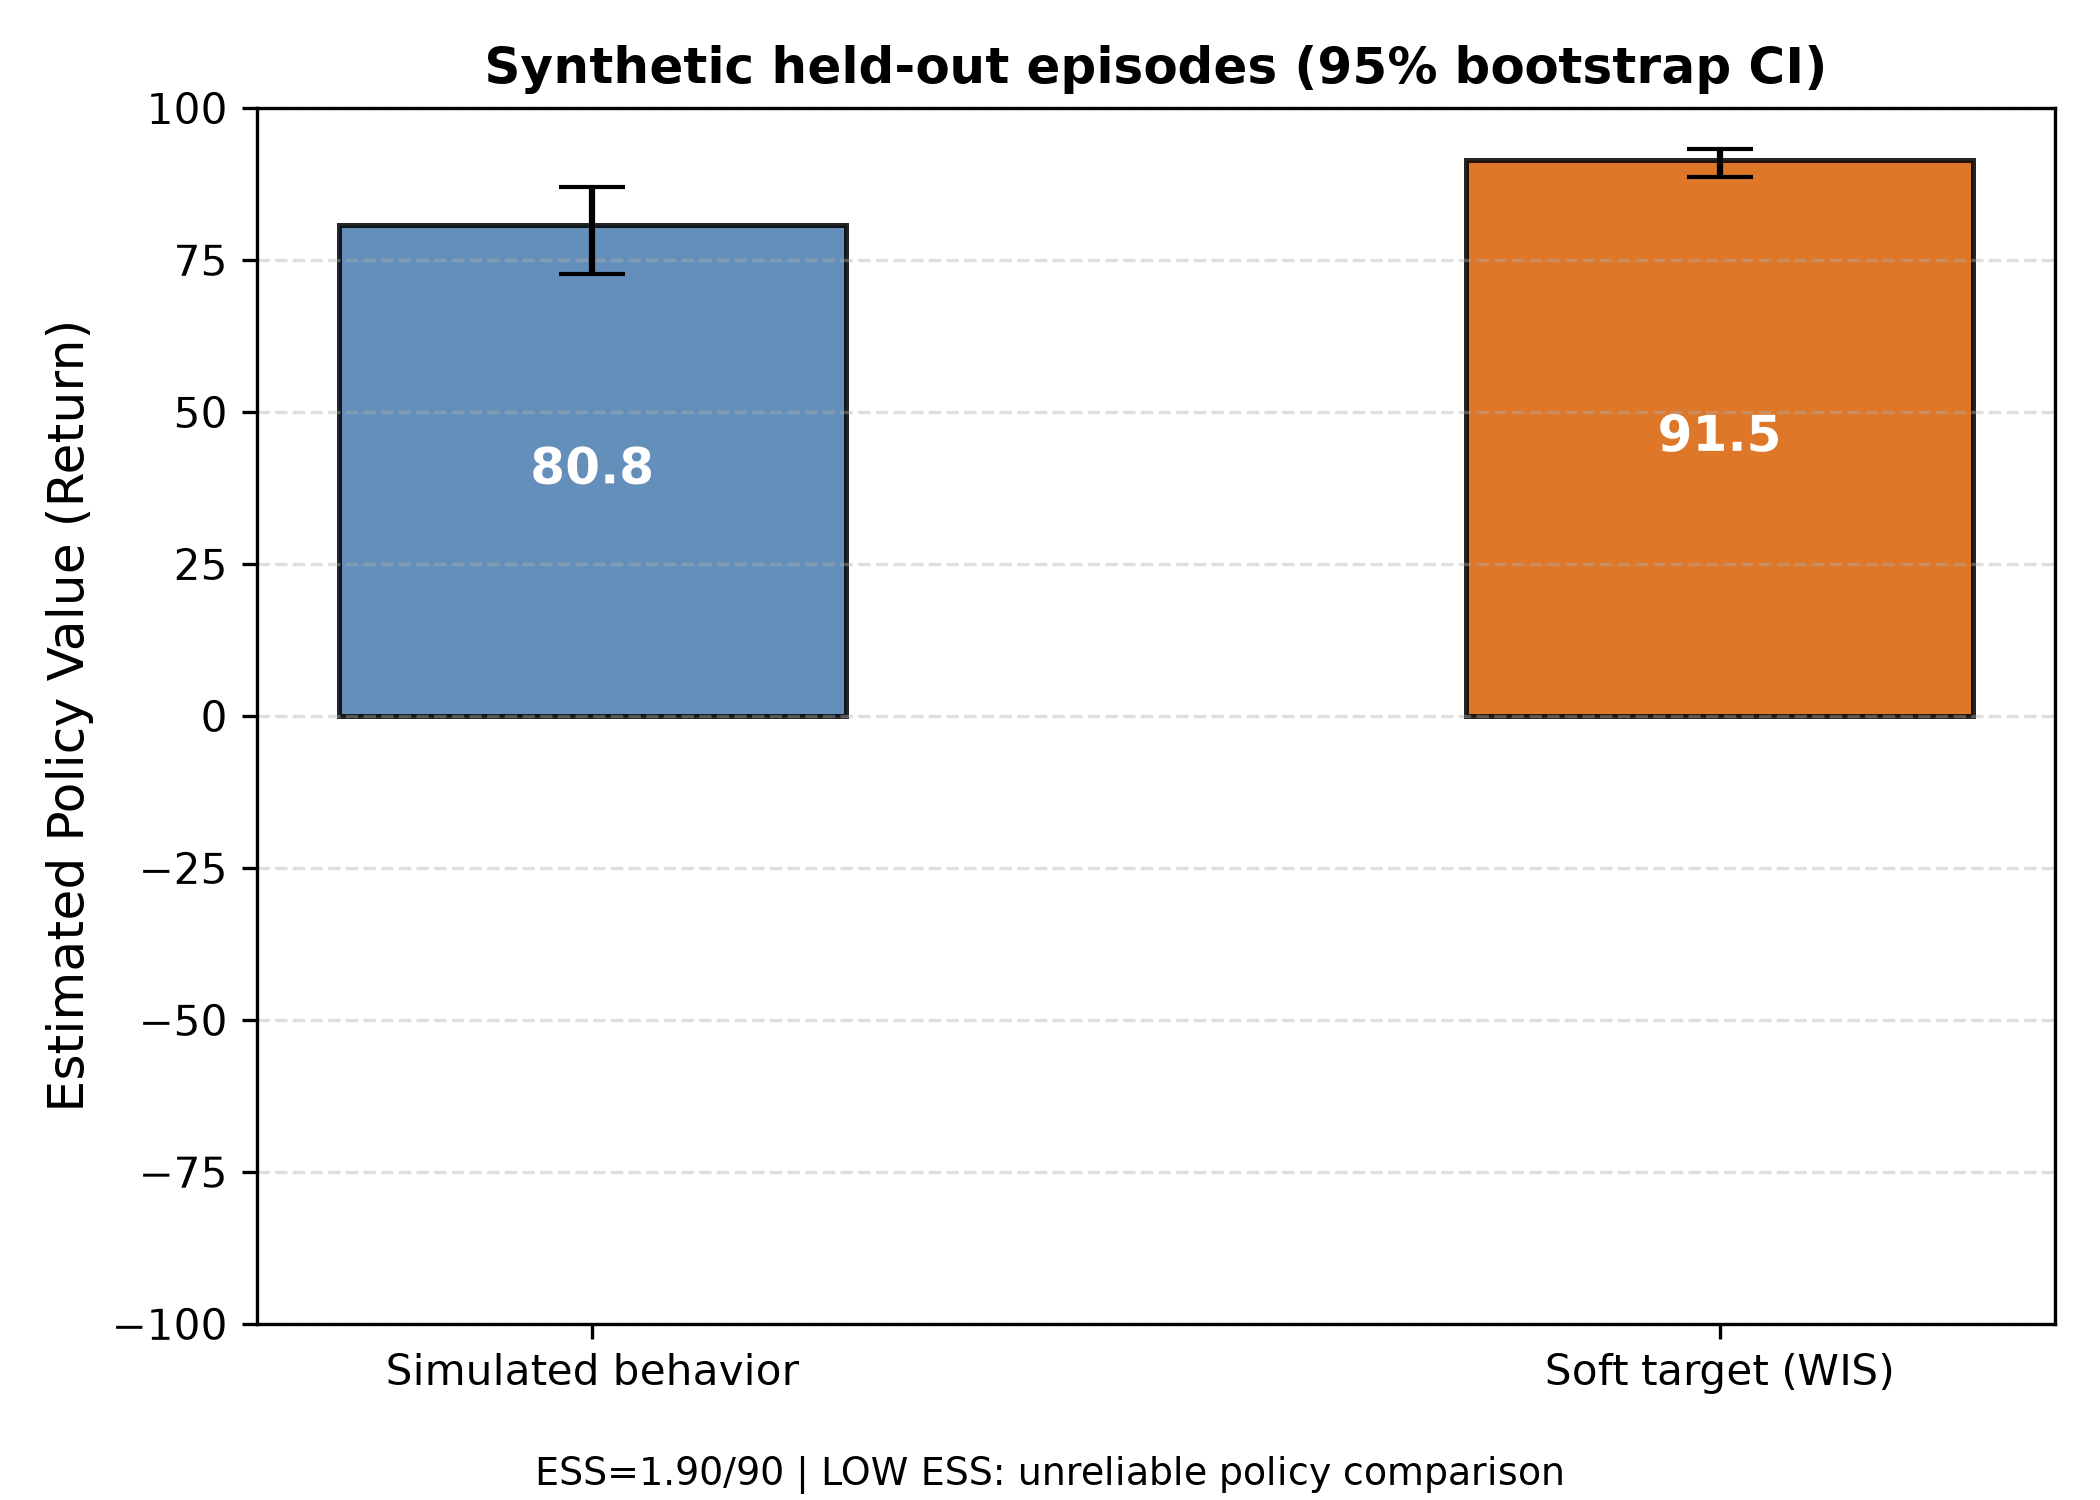

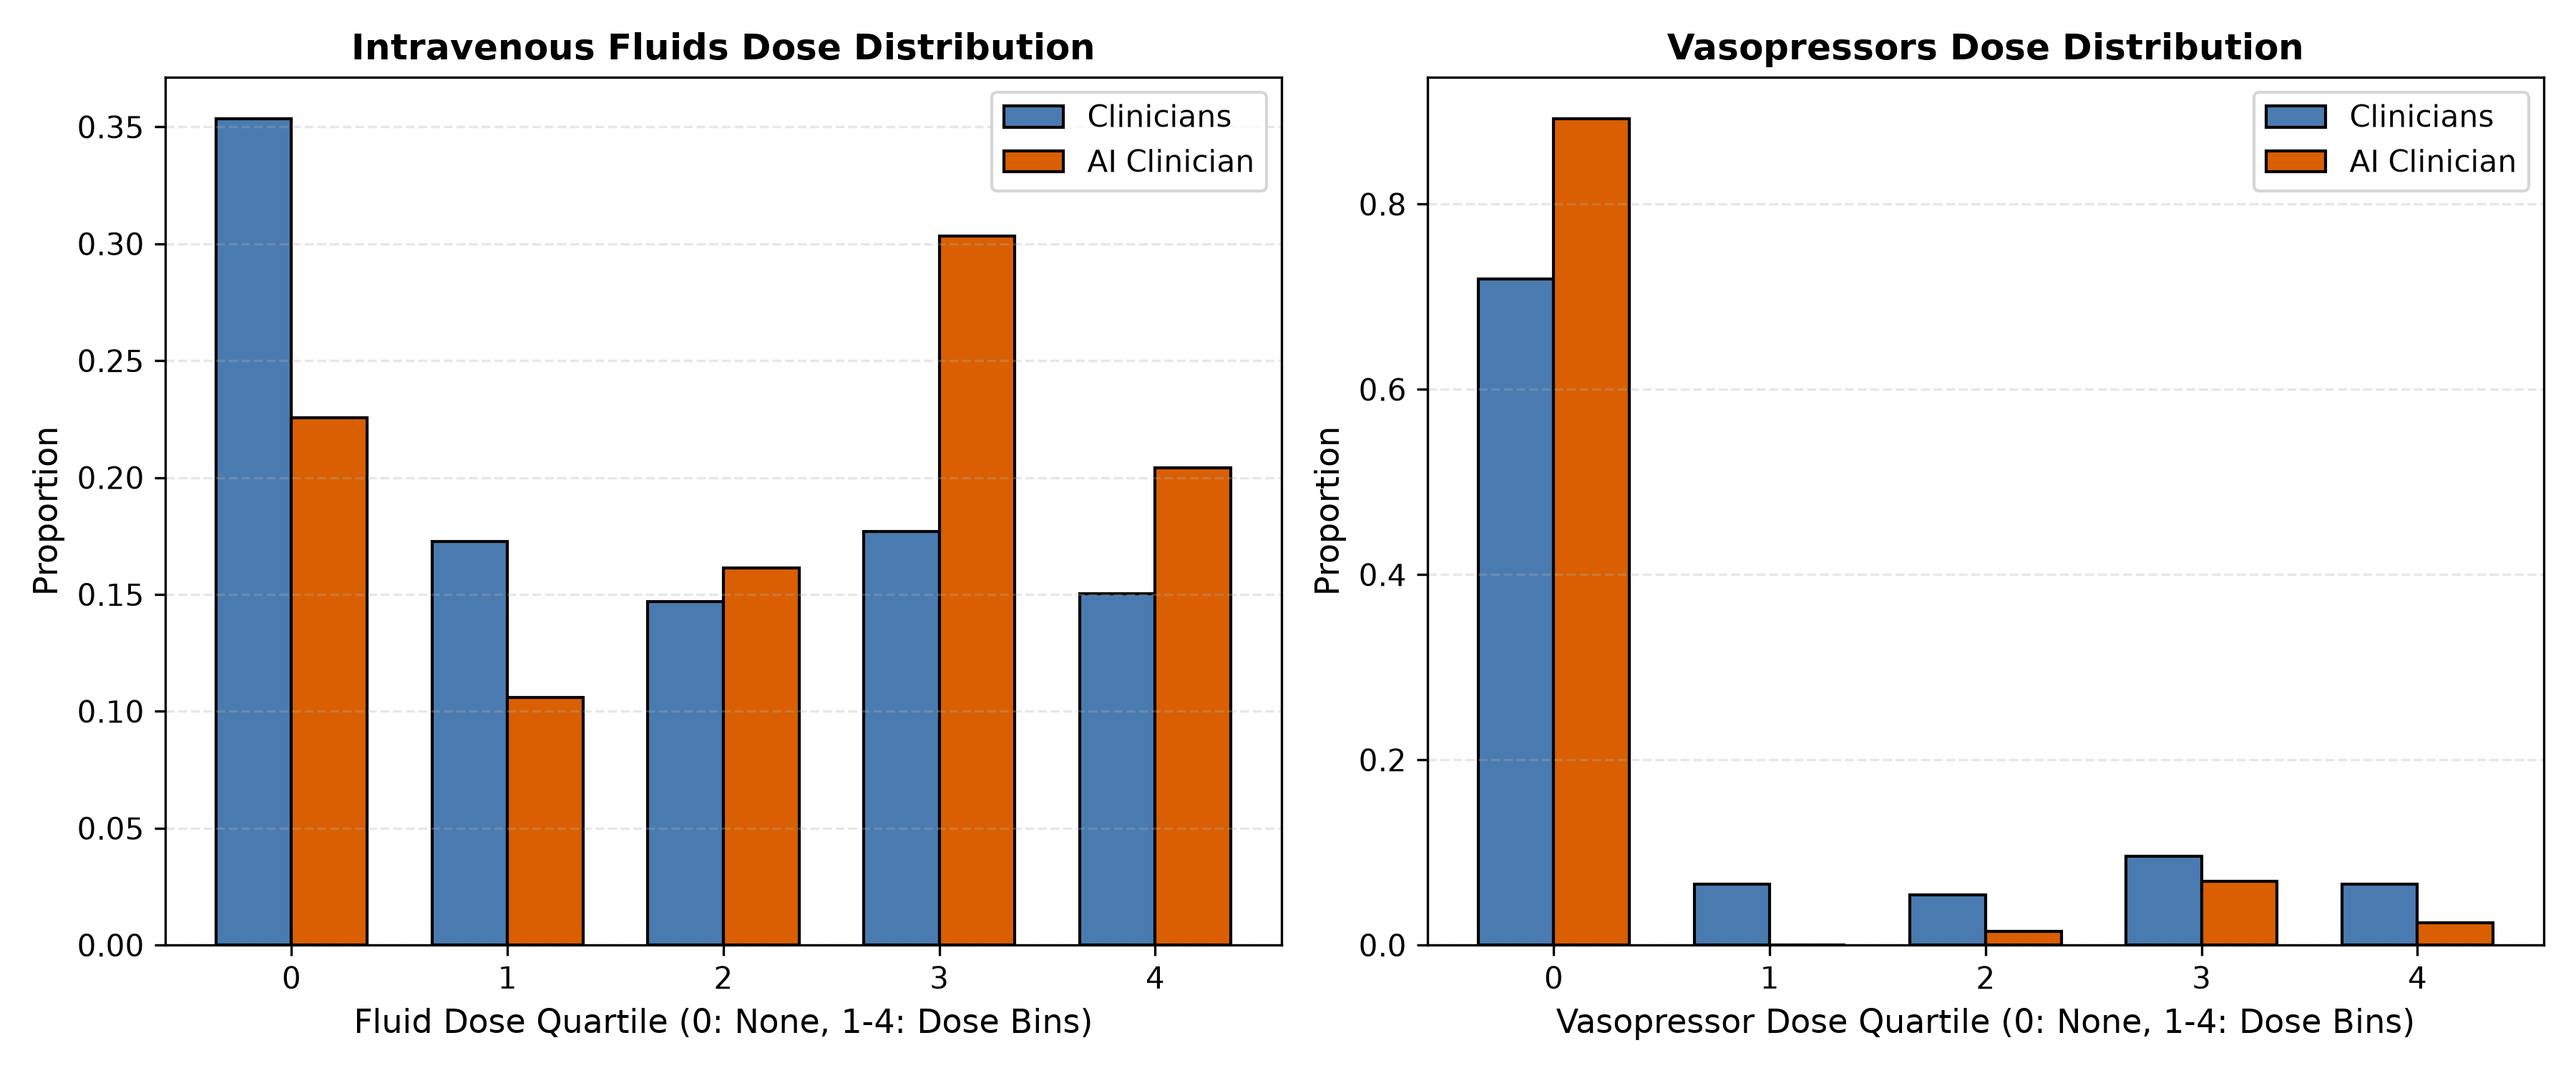

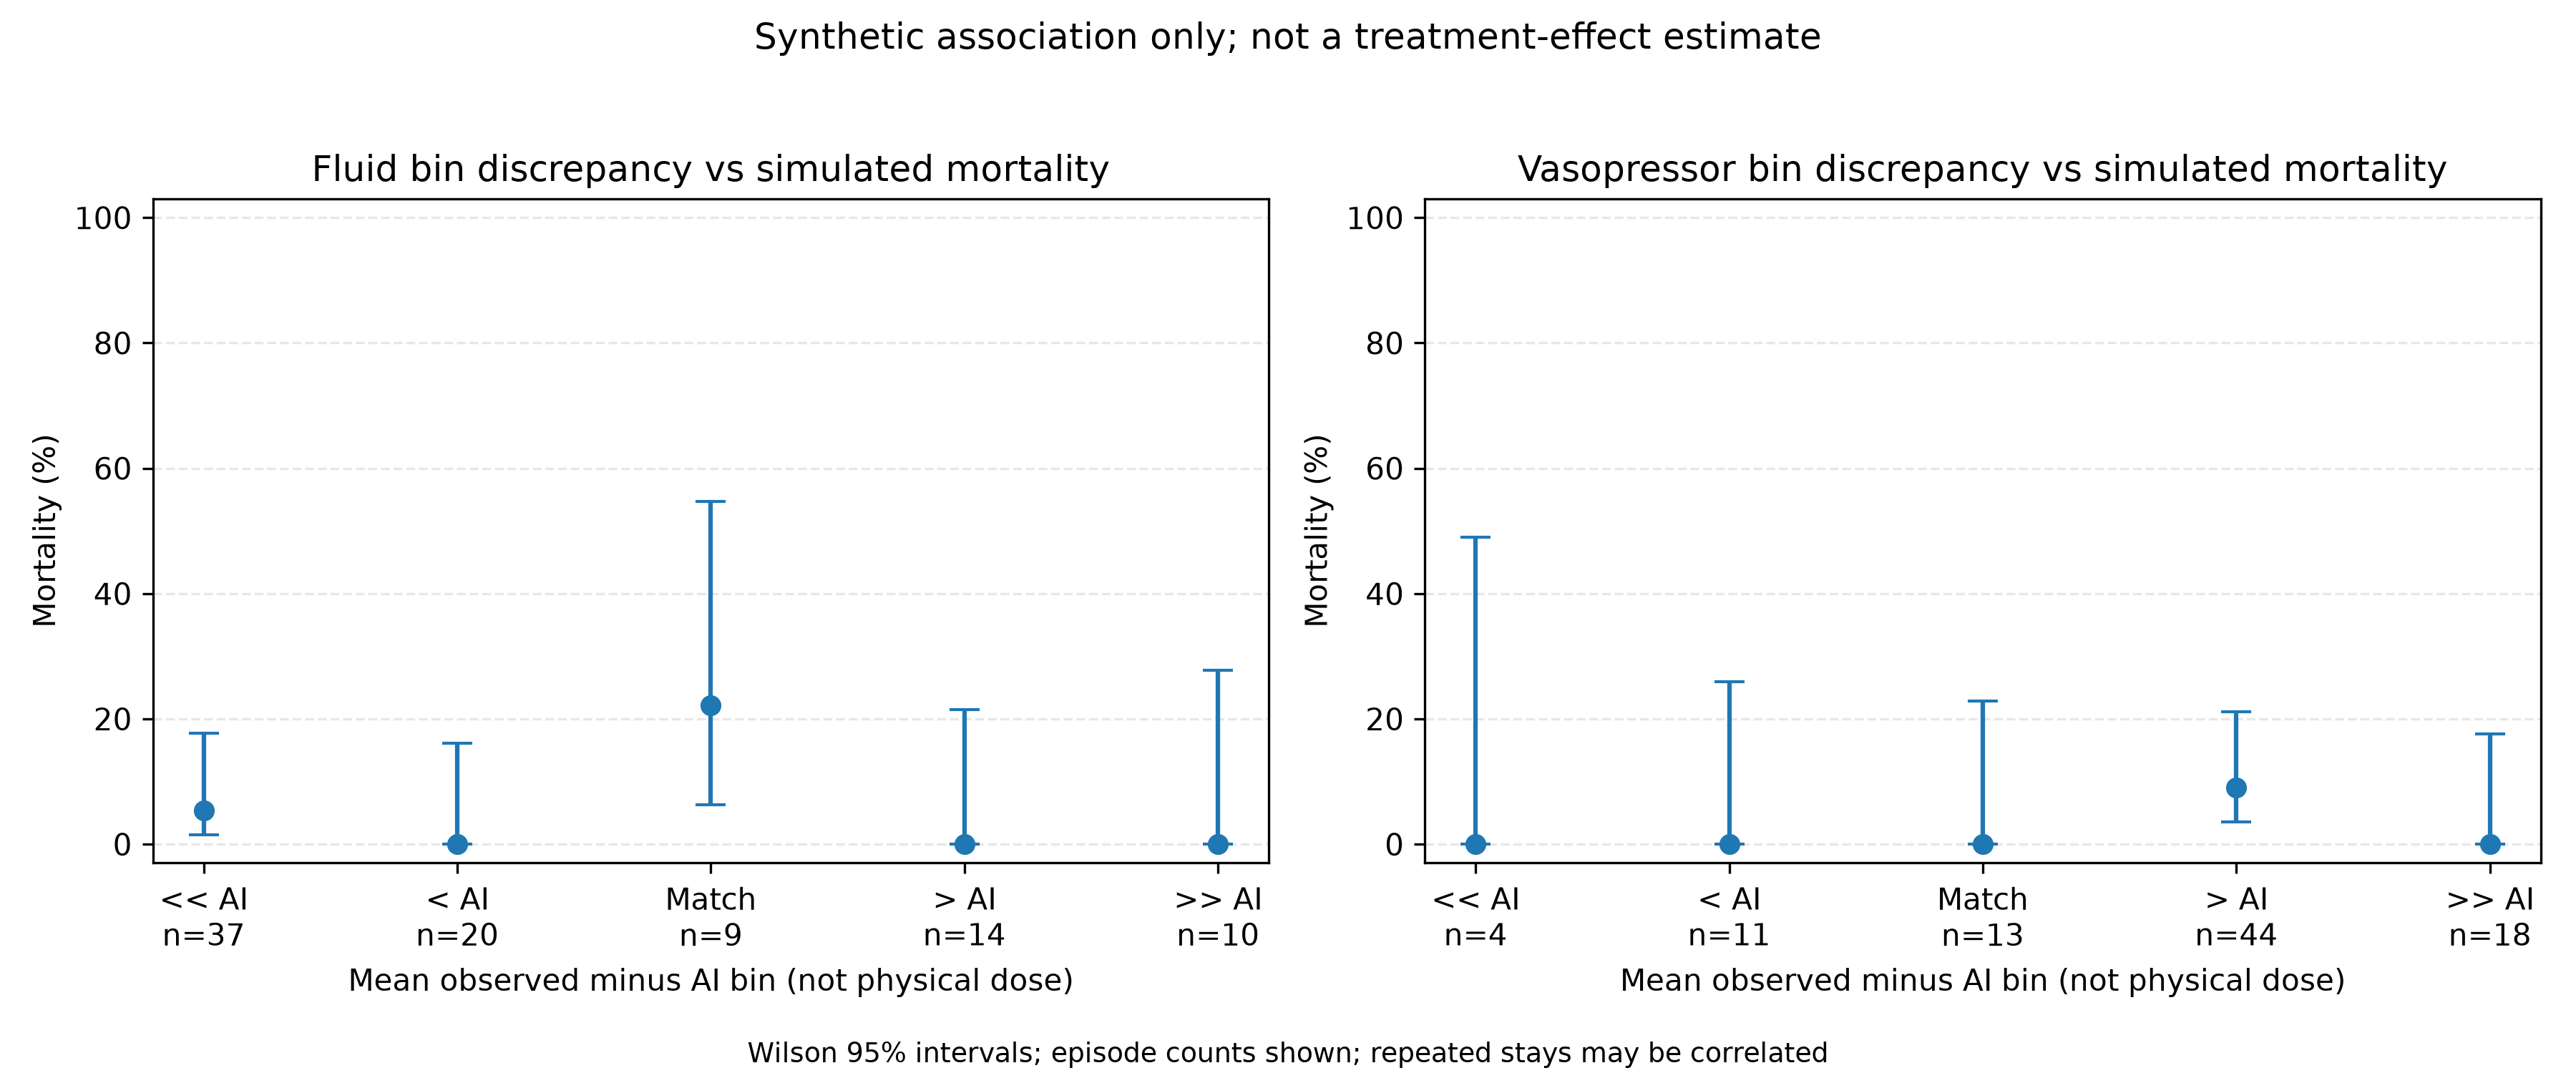

,f_diff,sum,count,mortality,ci_lower,ci_upper,treatment,v_diff
0,<< AI,2,37,0.054054,1.495098e-02,0.177047,Fluid,NaN
1,< AI,0,20,0.000000,0.000000e+00,0.161125,Fluid,NaN
2,Match,2,9,0.222222,6.322511e-02,0.547411,Fluid,NaN
3,> AI,0,14,0.000000,1.387779e-17,0.215311,Fluid,NaN
4,>> AI,0,10,0.000000,0.000000e+00,0.277533,Fluid,NaN
5,NaN,0,4,0.000000,0.000000e+00,0.489891,Vasopressor,<< AI
6,NaN,0,11,0.000000,0.000000e+00,0.258833,Vasopressor,< AI
7,NaN,0,13,0.000000,0.000000e+00,0.228095,Vasopressor,Match
8,NaN,4,44,0.090909,3.592219e-02,0.211592,Vasopressor,> AI
9,NaN,0,18,0.000000,0.000000e+00,0.175879,Vasopressor,>> AI


In [5]:
for filename in ['policy_value_comparison.png', 'action_distribution.png', 'dose_excess_vs_mortality.png']:
    display(Image(filename=str(output / 'figures' / filename)))
display(pd.read_csv(output / 'figures/mortality_bin_summary.csv'))


## Presentation limits

This simplified 75-state/30-feature synthetic demonstration is inspired by the paper, not a clinical reproduction. Real-data extraction, confounding adjustment, prospective validation and HCOPE guarantees are not implemented. Reward is not survival percentage. Low ESS prevents a credible claim that the target policy outperforms clinicians.